# 05 · Are large storms associated with longer payment timelines?
**Venkat Repaka and Ritik Gaire · NFIP flood claims**

**Question:** do bigger storms go with longer waits for the latest recorded payment?

We measure days from claim opening to the *latest* recorded payment. This is not the time to the first payment, and it does not prove the claim is closed. We compare storms, then claim sizes, and ask what the data can and cannot tell us.

**Learning bridge:** EDA found a few dominant events. We now aggregate claims by event, compare typical and extreme timelines, then ask whether claim size explains part of the event difference. This uses lecture 03 aggregation and lecture 07 event-separated evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

### Step 1 · Define the observed timeline before comparing groups
We keep negative and recent timelines visible in the preparation checks, then define the comparison sample. A latest payment date is not a closure date.

In [2]:
d=df[df.amountPaidOnBuildingClaim>0].copy()
d['payment_days']=(d.mostRecentPaymentDate-d.openDate).dt.days
print('Negative timelines excluded:',d.payment_days.lt(0).sum())
d=d[d.payment_days.ge(0)&d.loss_year.le(2024)].copy()
sizes=df[df.floodEvent.notna()].floodEvent.value_counts()
d['storm_size']=d.floodEvent.map(sizes)
d['event']=d.floodEvent.fillna('no named event')
d['within_90']=d.payment_days.le(90)
print(f'Paid claims with valid dates, 2020–2024: {len(d):,}')
display(d.groupby('loss_year').payment_days.agg(['size','median','mean']).round(1))

Negative timelines excluded: 12


Paid claims with valid dates, 2020–2024: 202,497


,size,median,mean
loss_year,,,
2020,24011,44.000,94.700
2021,34727,54.000,104.000
2022,44758,100.000,186.500
2023,16267,57.000,102.200
2024,82734,101.000,145.100


### Step 2 · A mean can be pulled by late supplements
Before using one average to summarize waiting time, compare the mean, median and upper percentiles. Long tails are a reason to report several measures, not a reason to delete every long case.

In [3]:
display(d.payment_days.describe(percentiles=[.5,.75,.9,.99]).to_frame('days to latest payment').round(1))

,days to latest payment
count,"202,497.000"
mean,137.800
std,181.300
min,0.000
50%,77.000
75%,146.000
90%,327.000
99%,958.000
max,"2,302.000"


## 1. Compare named events
We exclude 2025 to allow more follow-up, but this does not fully solve incomplete follow-up. A claim without payment is absent from this analysis; a paid claim may still receive another payment. We cannot estimate time to final settlement from the available dates alone.

### Step 3 · Aggregate the same quantity by event
The event table makes the unit of comparison explicit: an event has many paid claims.

In [4]:
storms=d[d.floodEvent.notna()].groupby('event').agg(paid_claims=('id','size'),all_claims=('storm_size','first'),
    median_days=('payment_days','median'),within_90_days=('within_90','mean'),
    median_payment=('amountPaidOnBuildingClaim','median'))
storms=storms[storms.paid_claims>=100]
display(storms.sort_values('all_claims',ascending=False).head(12).round(2))

,paid_claims,all_claims,median_days,within_90_days,median_payment
event,,,,,
Hurricane Helene,50438,"58,090.000",116.000,0.350,"94,530.140"
Hurricane Ian,37103,"48,824.000",110.000,0.400,"70,665.190"
Hurricane Ida,21650,"28,318.000",61.000,0.710,"26,051.640"
Hurricane Milton,16252,"21,675.000",100.000,0.430,"43,031.600"
Hurricane Sally,6124,"8,120.000",52.000,0.750,"14,757.720"
Hurricane Idalia,4775,"5,522.000",59.000,0.710,"63,105.060"
Hurricane Eta,2829,"3,677.000",53.000,0.780,"19,818.280"
April Florida Flooding,3002,"3,443.000",68.000,0.640,"59,461.440"
2021 Mid-Spring Severe Storms,3081,"3,404.000",44.000,0.800,"52,471.750"


### Step 4 · Visualize event size and the long tail
Each event point has the same definition, while the histogram shows variation among individual claims.

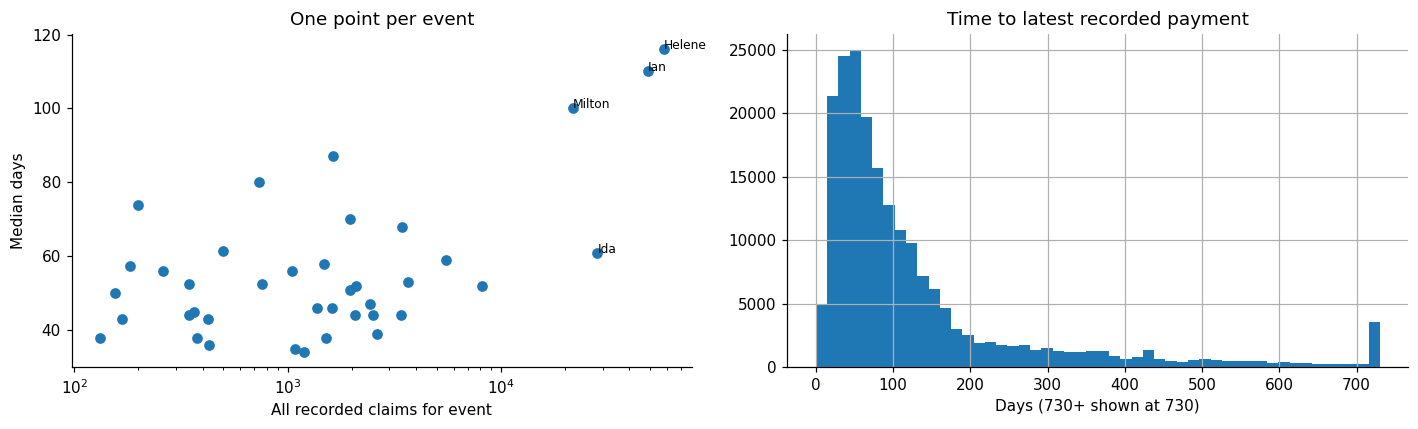

Event-level correlation: 0.569


In [5]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].scatter(storms.all_claims,storms.median_days)
for name in storms.nlargest(4,'all_claims').index:
    ax[0].annotate(name.replace('Hurricane ',''),(storms.loc[name,'all_claims'],storms.loc[name,'median_days']),fontsize=8)
ax[0].set(xscale='log',xlabel='All recorded claims for event',ylabel='Median days',title='One point per event')
d.payment_days.clip(upper=730).hist(bins=50,ax=ax[1]);ax[1].set(xlabel='Days (730+ shown at 730)',title='Time to latest recorded payment')
plt.tight_layout();plt.show()
print('Event-level correlation:',round(np.corrcoef(np.log10(storms.all_claims),storms.median_days)[0,1],3))
save_table(storms,'05_event_timelines')

## 2. Large storms and claim size
The 20,000-claim line is a descriptive grouping used in this project. There are few events near this line, so the data do not establish a capacity threshold. We report both a pooled median across claims and a median across event medians. They give different weight to large storms.

In [6]:
d['storm_group']=pd.cut(d.storm_size,[0,1000,5000,20000,np.inf],labels=['under 1,000','1,000–5,000','5,000–20,000','over 20,000']).astype('string').fillna('no named event')
pooled=d.groupby('storm_group').agg(claims=('id','size'),events=('event','nunique'),median_days=('payment_days','median'),within_90=('within_90','mean'))
display(pooled.round(3))
storms['over_20000']=storms.all_claims.gt(20000)
display(storms.groupby('over_20000').median_days.agg(events='size',median_of_event_medians='median'))
big=d[d.event.isin(sizes.head(4).index)].copy()
big['payment_band']=pd.cut(big.amountPaidOnBuildingClaim,[0,10000,50000,100000,np.inf],labels=['up to $10k','$10k–50k','$50k–100k','over $100k'])
display(big.pivot_table(index='payment_band',columns='event',values='payment_days',aggfunc='median',observed=True).round(0))

,claims,events,median_days,within_90
storm_group,,,,
"1,000–5,000",28979,18,50.000,0.757
"5,000–20,000",10899,2,55.000,0.733
no named event,32484,1,46.000,0.780
"over 20,000",125443,4,102.000,0.440
"under 1,000",4692,31,53.000,0.727


,events,median_of_event_medians
over_20000,,
False,35,50.000
True,4,105.000


event,Hurricane Helene,Hurricane Ian,Hurricane Ida,Hurricane Milton
payment_band,,,,
up to $10k,74.000,68.000,46.000,76.000
$10k–50k,105.000,96.000,57.000,97.000
$50k–100k,113.000,106.000,74.000,104.000
over $100k,135.000,146.000,102.000,125.000


### Step 5 · Why compare claim sizes inside an event?
A large event could have more difficult claims. The payment-band table holds the event fixed while comparing observed claim size. It reduces one mixing problem but does not establish a cause of delay.

## 3. A retrospective model with event-separated evaluation
The final payment amount and total event size are known after the event. We use them to describe the association, not to claim a first-day forecasting tool. We hold out entire named events, rather than mixing their claims between fitting and evaluation.

In [7]:
from sklearn.model_selection import GroupShuffleSplit
named=d[d.floodEvent.notna()].copy()
named['log_storm_size']=np.log1p(named.storm_size)
named['log_final_payment']=np.log1p(named.amountPaidOnBuildingClaim)
a,b=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED).split(named,groups=named.floodEvent))
progression={'claim size only':['log_final_payment'],
             'claim size + event size':['log_final_payment','log_storm_size'],
             'plus building and place':['log_storm_size','log_final_payment','building_age','state','occupancy','zone','report_lag_days']}
timing_rows=[]
for label,cc in progression.items():
    model=model_for(named[cc],'regression').fit(named.iloc[a][cc],named.iloc[a].payment_days)
    pp=model.predict(named.iloc[b][cc])
    timing_rows.append({'step':label,**regression_scores(named.iloc[b].payment_days,pp)})
timing_rows.append({'step':'training median',**regression_scores(named.iloc[b].payment_days,np.full(len(b),named.iloc[a].payment_days.median()))})
timing=pd.DataFrame(timing_rows).set_index('step').rename(columns={'MAE $':'MAE days','median error $':'median error days'})
display(timing.round(2));save_table(timing,'05_model_progression')
print('Held-out events:',named.iloc[b].floodEvent.nunique())

,R2,MAE days,median error days
step,,,
claim size only,0.040,98.630,73.450
claim size + event size,0.030,95.220,70.390
plus building and place,0.060,86.310,57.530
training median,-0.000,82.280,51.000


Held-out events: 14


In [8]:
base=timing.loc['training median']
models=timing.drop('training median')
display(Markdown(
    f"**Reading the table.** A fixed guess of the training median ({named.iloc[a].payment_days.median():.0f} days) has an average error of **{base['MAE days']:.0f} days**. "
    f"The best model has **{models['MAE days'].min():.0f} days**. "
    + ("The models are better than the fixed guess on average error, but only a little. " if models['MAE days'].min()<base['MAE days'] else
       "No model beats the fixed guess on average error. ")
    + "Claim size and storm size explain very little of how long one claim waits. Most of the wait depends on facts we do not have, such as the type of damage, disputes and later extra payments."))

**Reading the table.** A fixed guess of the training median (95 days) has an average error of **82 days**. The best model has **86 days**. No model beats the fixed guess on average error. Claim size and storm size explain very little of how long one claim waits. Most of the wait depends on facts we do not have, such as the type of damage, disputes and later extra payments.

## 4. Answer and limits
**Answer.** The four biggest storms have longer waits to the latest payment (about 100 days, against about 50 days for smaller storms). Larger claims also wait longer inside the same storm. But Hurricane Ida was large and still faster, so size alone does not explain the wait.

**What we cannot say.** We cannot say that staff capacity caused the delay, that 20,000 claims is a real limit, or that more adjusters would help. The four large storms are mostly in Florida, so storm size, place and year are mixed together. A claim can also receive a later extra payment, so "latest payment" is not the end of the claim.

**What we would need.** First-payment dates, closing dates, claims that are still open, and payment history at fixed times. With these, a time-to-event analysis could include claims that are still waiting.

### Decision ledger
We kept the median because the timeline is skewed, kept event-level aggregation because storms differ, and checked claim-size bands because complexity can be mixed with event size. We discarded a causal “capacity limit” conclusion: event size, place and final payment information do not identify staff capacity. The next notebook uses the same raw-to-adjusted logic for floor elevation.

### Result in plain English

The median timeline to the latest recorded payment is **116 days for Helene**, **110 for Ian**, **100 for Milton** and **61 for Ida**. Ida shows why event size alone is not a complete explanation. Claim complexity, location and supplements may also matter. These dates do not establish first-payment time, final closure or a staffing capacity threshold.